# Respostas às perguntas analíticas (P1, P2 e P3)

**Projeto:** Dengue no Brasil em 2026: pico de casos, gravidade e perfil dos pacientes
**Grupo:** Bruna da Silva Carnelossi, João Pedro de Souza Quintiliano da Silva, João Victor Carvalho de Freitas, Matheus Henrique Heinzen

Este notebook **não faz parte das entregas do RA1 nem do RA2**: o RA1 proíbe agregações, indicadores, visualizações e conclusões, e o RA2 trata de streaming. Ele responde as três perguntas formuladas no RA1 a partir do conjunto preparado (`dados/preparados/dengue_brasil_2026.parquet`) e serve de base para o RA3 (Data Visualization).

Definições herdadas do RA1:

- **Caso** = notificação de caso provável de dengue (o arquivo público não traz casos descartados).
- **Caso grave** = classificação final "dengue com sinais de alarme" ou "dengue grave". A proporção é calculada sobre os casos classificados como dengue; inconclusivos e casos sem classificação ficam fora do denominador.
- **Estado** = UF de residência.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RAIZ = Path.cwd().parent
ARQUIVO_PREPARADO = RAIZ / "dados" / "preparados" / "dengue_brasil_2026.parquet"
assert ARQUIVO_PREPARADO.exists(), "Execute antes o notebook do RA1, que gera o conjunto preparado."

dengue = pd.read_parquet(ARQUIVO_PREPARADO)
classificados = dengue[dengue["caso_grave"].notna()].copy()
classificados["caso_grave"] = classificados["caso_grave"].astype(bool)


def milhar(numero):
    return f"{numero:,.0f}".replace(",", ".")


def pct(valor):
    return f"{valor:.2%}".replace(".", ",")


print(f"Notificações no conjunto preparado:     {milhar(len(dengue))}")
print(f"Casos classificados como dengue:        {milhar(len(classificados))}")
print(f"Casos graves:                           {milhar(classificados['caso_grave'].sum())} ({pct(classificados['caso_grave'].mean())})")
print(f"Período dos sintomas:                   {dengue['dt_sintomas'].min().date()} a {dengue['dt_sintomas'].max().date()}")

Notificações no conjunto preparado:     470.221
Casos classificados como dengue:        365.519
Casos graves:                           12.856 (3,52%)
Período dos sintomas:                   2026-01-04 a 2026-10-03


---

## P1. Em que mês de 2026 os casos atingiram o pico e qual estado concentrou mais casos?

**Medida:** número de notificações por mês de início dos sintomas (`mes_sintomas`) e por UF de residência (`uf_residencia`). Todas as notificações entram na contagem, inclusive as ainda sem classificação final.

> Outubro está incompleto: o arquivo vai até 04/10/2026. Os meses mais recentes também tendem a crescer em atualizações futuras do SINAN, porque parte das notificações é digitada com atraso.

NOTIFICAÇÕES POR MÊS DE INÍCIO DOS SINTOMAS


,notificações,% do ano
mes_sintomas,,
2026-01,"34,562",7.4%
2026-02,"49,161",10.5%
2026-03,"77,187",16.4%
2026-04,"84,050",17.9%
2026-05,"78,017",16.6%
2026-06,"47,443",10.1%
2026-07,"36,276",7.7%
2026-08,"33,300",7.1%
2026-09,"29,913",6.4%


Mês do pico: 2026-04 (84.050 notificações, 17,87% do ano)


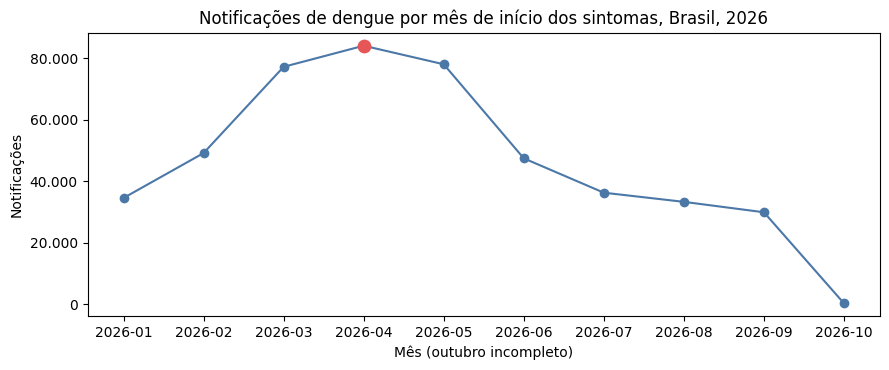

In [2]:
por_mes = dengue.groupby("mes_sintomas").size().rename("notificações").to_frame()
por_mes["% do ano"] = por_mes["notificações"] / por_mes["notificações"].sum()
mes_pico = por_mes["notificações"].idxmax()

print("NOTIFICAÇÕES POR MÊS DE INÍCIO DOS SINTOMAS")
display(por_mes.style.format({"notificações": "{:,.0f}", "% do ano": "{:.1%}"}))
print(f"Mês do pico: {mes_pico} ({milhar(por_mes.loc[mes_pico, 'notificações'])} notificações, {pct(por_mes.loc[mes_pico, '% do ano'])} do ano)")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(por_mes.index, por_mes["notificações"], marker="o", color="#4C78A8")
ax.scatter([mes_pico], [por_mes.loc[mes_pico, "notificações"]], color="#E45756", zorder=3, s=80)
ax.set_title("Notificações de dengue por mês de início dos sintomas, Brasil, 2026")
ax.set_ylabel("Notificações")
ax.set_xlabel("Mês (outubro incompleto)")
ax.yaxis.set_major_formatter(lambda valor, _: milhar(valor))
plt.tight_layout()
plt.show()

AS 10 UFs COM MAIS NOTIFICAÇÕES (UF DE RESIDÊNCIA)


,notificações,% do país,% acumulado
uf_residencia,,,
GO,"115,161",24.5%,24.5%
SP,"68,330",14.5%,39.0%
MG,"63,367",13.5%,52.5%
BA,"24,856",5.3%,57.8%
PE,"23,254",4.9%,62.7%
ES,"19,944",4.2%,67.0%
PI,"19,089",4.1%,71.0%
CE,"18,370",3.9%,74.9%
TO,"14,918",3.2%,78.1%


Estado com mais casos: GO (115.161 notificações, 24,49% do país)


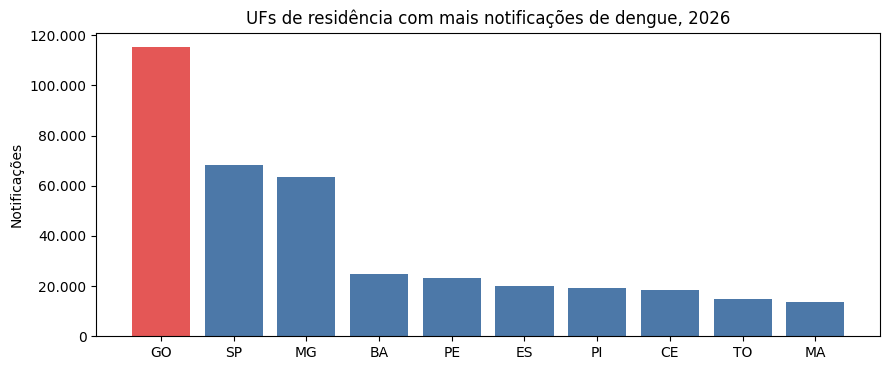

In [3]:
por_uf = dengue.groupby("uf_residencia", observed=True).size().sort_values(ascending=False).rename("notificações").to_frame()
por_uf["% do país"] = por_uf["notificações"] / por_uf["notificações"].sum()
por_uf["% acumulado"] = por_uf["% do país"].cumsum()
uf_lider = por_uf.index[0]

print("AS 10 UFs COM MAIS NOTIFICAÇÕES (UF DE RESIDÊNCIA)")
display(por_uf.head(10).style.format({"notificações": "{:,.0f}", "% do país": "{:.1%}", "% acumulado": "{:.1%}"}))
print(f"Estado com mais casos: {uf_lider} ({milhar(por_uf.loc[uf_lider, 'notificações'])} notificações, {pct(por_uf.loc[uf_lider, '% do país'])} do país)")

top10 = por_uf.head(10)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(top10.index.astype(str), top10["notificações"], color=["#E45756"] + ["#4C78A8"] * 9)
ax.set_title("UFs de residência com mais notificações de dengue, 2026")
ax.set_ylabel("Notificações")
ax.yaxis.set_major_formatter(lambda valor, _: milhar(valor))
plt.tight_layout()
plt.show()

In [4]:
pico_por_uf = (
    dengue[dengue["uf_residencia"].isin(top10.index)]
    .groupby(["uf_residencia", "mes_sintomas"], observed=True).size()
    .rename("notificações").reset_index()
    .sort_values("notificações", ascending=False)
    .drop_duplicates("uf_residencia")
    .set_index("uf_residencia")
    .loc[top10.index]
    .rename(columns={"mes_sintomas": "mês do pico na UF", "notificações": "notificações no mês do pico"})
)
print("MÊS DO PICO EM CADA UMA DAS 10 UFs COM MAIS CASOS")
display(pico_por_uf.style.format({"notificações no mês do pico": "{:,.0f}"}))

MÊS DO PICO EM CADA UMA DAS 10 UFs COM MAIS CASOS


,mês do pico na UF,notificações no mês do pico
uf_residencia,,
GO,2026-03,"22,817"
SP,2026-04,"13,563"
MG,2026-04,"14,050"
BA,2026-05,"4,611"
PE,2026-05,"4,090"
ES,2026-05,"3,874"
PI,2026-05,"4,595"
CE,2026-07,"4,497"
TO,2026-02,"2,694"


**Resposta P1:**

O **pico foi em abril de 2026**, com 84.050 notificações (17,9% do ano até 04/10). Março, abril e maio concentram juntos 50,9% dos casos: a curva sobe a partir de fevereiro, fica alta por três meses e cai a partir de junho.

**Goiás foi o estado com mais casos**: 115.161 notificações de residentes, 24,5% do país, cerca de 1,7 vez o total de São Paulo (68.330, 14,5%) e 1,8 vez o de Minas Gerais (63.367, 13,5%). Só essas três UFs somam 52,5% das notificações de 2026.

O pico não aconteceu ao mesmo tempo em todo o país. Goiás chegou ao máximo em março, um mês antes do pico nacional; São Paulo e Minas, em abril; Bahia, Pernambuco, Espírito Santo e Piauí, em maio; e o Ceará, só em julho. O pico nacional de abril é, portanto, a soma de epidemias estaduais defasadas no tempo.

---

## P2. A proporção de casos graves é maior entre homens ou entre mulheres?

**Medida:** proporção de casos graves (`caso_grave`) entre os casos classificados como dengue, por sexo. Casos com sexo ignorado ficam fora.

Para saber se a diferença entre os dois grupos é maior do que a esperada pelo acaso, usamos o **teste z para duas proporções**, o teste padrão para comparar uma proporção entre dois grupos independentes.

In [5]:
com_sexo = classificados[classificados["sexo"].notna()]
gravidade_sexo = com_sexo.groupby("sexo", observed=True)["caso_grave"].agg(casos="size", graves="sum")
gravidade_sexo["% graves"] = gravidade_sexo["graves"] / gravidade_sexo["casos"]

print("PROPORÇÃO DE CASOS GRAVES POR SEXO")
display(gravidade_sexo.style.format({"casos": "{:,.0f}", "graves": "{:,.0f}", "% graves": "{:.2%}"}))

f, m = gravidade_sexo.loc["Feminino"], gravidade_sexo.loc["Masculino"]
p_comum = (f["graves"] + m["graves"]) / (f["casos"] + m["casos"])
erro = math.sqrt(p_comum * (1 - p_comum) * (1 / f["casos"] + 1 / m["casos"]))
z = (f["% graves"] - m["% graves"]) / erro
p_valor = math.erfc(abs(z) / math.sqrt(2))
razao = f["% graves"] / m["% graves"]

print("TESTE Z PARA DUAS PROPORÇÕES")
print("─" * 50)
print(f"Diferença (F − M):        {(f['% graves'] - m['% graves']) * 100:+.2f} pontos percentuais")
print(f"Razão (F ÷ M):            {razao:.2f}")
print(f"z = {z:.2f} | p-valor = {p_valor:.2e}")

sem_duplicatas = com_sexo[~com_sexo["possivel_duplicata"]]
sensibilidade = sem_duplicatas.groupby("sexo", observed=True)["caso_grave"].mean()
print(f"\nSensibilidade, sem possíveis duplicatas: Feminino {pct(sensibilidade['Feminino'])} | Masculino {pct(sensibilidade['Masculino'])}")

PROPORÇÃO DE CASOS GRAVES POR SEXO


,casos,graves,% graves
sexo,,,
Feminino,"197,764","7,112",3.60%
Masculino,"167,599","5,740",3.42%


TESTE Z PARA DUAS PROPORÇÕES
──────────────────────────────────────────────────
Diferença (F − M):        +0.17 pontos percentuais
Razão (F ÷ M):            1.05
z = 2.80 | p-valor = 5.08e-03



Sensibilidade, sem possíveis duplicatas: Feminino 3,59% | Masculino 3,42%


**Resposta P2:**

A proporção de casos graves é **ligeiramente maior entre mulheres**: 3,60% (7.112 de 197.764) contra 3,42% entre homens (5.740 de 167.599). A diferença é de 0,17 ponto percentual, e as mulheres têm uma proporção 5% maior que a dos homens (razão de 1,05).

O teste z indica que a diferença não é fruto do acaso (z = 2,80; p = 0,005), mas isso se deve sobretudo ao tamanho da base: com mais de 365 mil casos, até diferenças pequenas ficam estatisticamente significativas. **Na prática, a gravidade é muito parecida entre os sexos.** O resultado não muda ao retirar as possíveis duplicatas (3,59% contra 3,42%).

---

## P3. A proporção de casos graves varia por faixa etária e pela presença de comorbidades?

**Medida:** proporção de casos graves por faixa etária, por diabetes e por hipertensão, entre os casos classificados como dengue. Casos sem informação sobre a comorbidade ficam fora da comparação daquela comorbidade.

Como diabetes e hipertensão são mais comuns em pessoas mais velhas, comparar só "com × sem comorbidade" misturaria o efeito da doença com o da idade. Por isso, a última tabela compara quem tem e quem não tem comorbidade **dentro de cada faixa etária**.

PROPORÇÃO DE CASOS GRAVES POR FAIXA ETÁRIA


,casos,graves,% graves
faixa_etaria,,,
0-4,"17,489",559,3.20%
5-14,"50,965","1,884",3.70%
15-29,"116,006","3,652",3.15%
30-44,"86,345","2,756",3.19%
45-59,"57,516","2,073",3.60%
60-74,"28,660","1,297",4.53%
75+,"8,527",635,7.45%


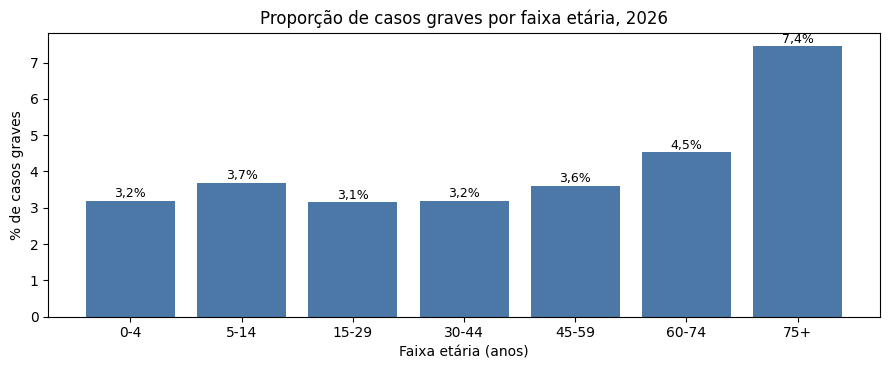

In [6]:
gravidade_idade = classificados.groupby("faixa_etaria", observed=True)["caso_grave"].agg(casos="size", graves="sum")
gravidade_idade["% graves"] = gravidade_idade["graves"] / gravidade_idade["casos"]

print("PROPORÇÃO DE CASOS GRAVES POR FAIXA ETÁRIA")
display(gravidade_idade.style.format({"casos": "{:,.0f}", "graves": "{:,.0f}", "% graves": "{:.2%}"}))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(gravidade_idade.index.astype(str), gravidade_idade["% graves"] * 100, color="#4C78A8")
for posicao, valor in enumerate(gravidade_idade["% graves"] * 100):
    ax.text(posicao, valor + 0.1, f"{valor:.1f}%".replace(".", ","), ha="center", fontsize=9)
ax.set_title("Proporção de casos graves por faixa etária, 2026")
ax.set_xlabel("Faixa etária (anos)")
ax.set_ylabel("% de casos graves")
plt.tight_layout()
plt.show()

In [7]:
linhas = []
for coluna, nome in [("diabetes", "Diabetes"), ("hipertensao", "Hipertensão")]:
    informados = classificados[classificados[coluna].notna()]
    for tem, rotulo in [(True, "com"), (False, "sem")]:
        grupo = informados[informados[coluna] == tem]
        linhas.append({"comorbidade": nome, "grupo": rotulo, "casos": len(grupo), "graves": int(grupo["caso_grave"].sum()), "% graves": grupo["caso_grave"].mean()})
gravidade_comorbidade = pd.DataFrame(linhas).set_index(["comorbidade", "grupo"])

print("PROPORÇÃO DE CASOS GRAVES COM E SEM COMORBIDADE")
display(gravidade_comorbidade.style.format({"casos": "{:,.0f}", "graves": "{:,.0f}", "% graves": "{:.2%}"}))
for nome in ["Diabetes", "Hipertensão"]:
    com, sem = gravidade_comorbidade.loc[(nome, "com"), "% graves"], gravidade_comorbidade.loc[(nome, "sem"), "% graves"]
    print(f"{nome}: {com / sem:.1f} vezes a proporção de graves de quem não tem")

PROPORÇÃO DE CASOS GRAVES COM E SEM COMORBIDADE


Diabetes: 2.2 vezes a proporção de graves de quem não tem
Hipertensão: 2.0 vezes a proporção de graves de quem não tem


PROPORÇÃO DE CASOS GRAVES POR FAIXA ETÁRIA E COMORBIDADE


comorbidade,com diabetes ou hipertensão,sem nenhuma das duas,razão (com ÷ sem)
faixa_etaria,,,
0-4,8.20%,3.14%,2.61
5-14,3.21%,3.70%,0.87
15-29,4.42%,3.13%,1.41
30-44,5.04%,3.06%,1.65
45-59,5.37%,3.17%,1.69
60-74,6.98%,3.16%,2.21
75+,11.40%,4.20%,2.71


Casos em cada célula:


comorbidade,com diabetes ou hipertensão,sem nenhuma das duas
faixa_etaria,,
0-4,183,"17,306"
5-14,405,"50,558"
15-29,"1,992","114,014"
30-44,"5,779","80,565"
45-59,"11,444","46,072"
60-74,"10,258","18,402"
75+,"3,842","4,685"


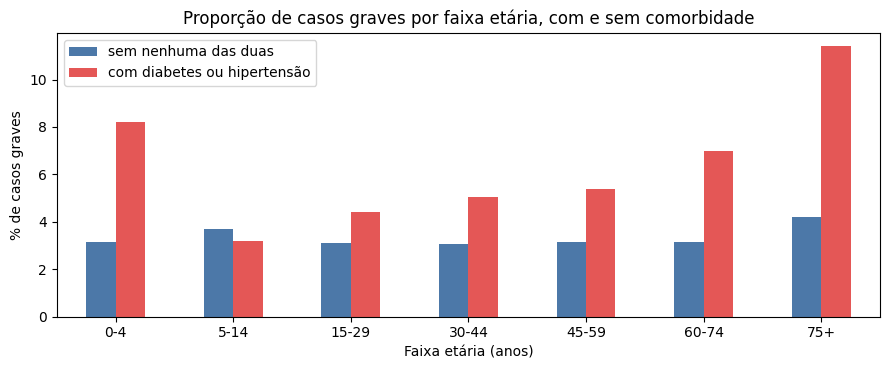

In [8]:
informados = classificados[classificados["diabetes"].notna() & classificados["hipertensao"].notna()].copy()
informados["comorbidade"] = (informados["diabetes"] | informados["hipertensao"]).map({True: "com diabetes ou hipertensão", False: "sem nenhuma das duas"})

por_faixa_e_comorbidade = informados.pivot_table(index="faixa_etaria", columns="comorbidade", values="caso_grave", aggfunc="mean", observed=True)
casos_por_celula = informados.pivot_table(index="faixa_etaria", columns="comorbidade", values="caso_grave", aggfunc="size", observed=True)
por_faixa_e_comorbidade["razão (com ÷ sem)"] = por_faixa_e_comorbidade["com diabetes ou hipertensão"] / por_faixa_e_comorbidade["sem nenhuma das duas"]

print("PROPORÇÃO DE CASOS GRAVES POR FAIXA ETÁRIA E COMORBIDADE")
display(por_faixa_e_comorbidade.style.format({"com diabetes ou hipertensão": "{:.2%}", "sem nenhuma das duas": "{:.2%}", "razão (com ÷ sem)": "{:.2f}"}))
print("Casos em cada célula:")
display(casos_por_celula.style.format("{:,.0f}"))

ax = (por_faixa_e_comorbidade[["sem nenhuma das duas", "com diabetes ou hipertensão"]] * 100).plot(kind="bar", figsize=(9, 3.8), color=["#4C78A8", "#E45756"], rot=0)
ax.set_title("Proporção de casos graves por faixa etária, com e sem comorbidade")
ax.set_xlabel("Faixa etária (anos)")
ax.set_ylabel("% de casos graves")
ax.legend(title="")
plt.tight_layout()
plt.show()

**Resposta P3:**

**Sim, varia, e as duas variáveis importam.**

**Faixa etária.** A proporção de graves fica perto de 3,2% dos 15 aos 44 anos, sobe a partir dos 45 (3,60%), chega a 4,53% entre 60 e 74 anos e a **7,45% acima dos 75**, mais que o dobro dos adultos jovens. Há também um valor mais alto entre 5 e 14 anos (3,70%) do que entre adultos jovens.

**Comorbidades.** Quem tem diabetes teve 7,29% de casos graves, contra 3,38% de quem não tem (2,2 vezes). Com hipertensão, foram 6,46% contra 3,27% (2,0 vezes).

**As duas juntas.** Como as comorbidades são mais comuns nos mais velhos, a comparação foi refeita dentro de cada faixa etária. Ter diabetes ou hipertensão aumenta a proporção de graves em quase todas as faixas, e o efeito cresce com a idade: 1,41 vez entre 15 e 29 anos, 1,69 vez entre 45 e 59 e **2,71 vezes acima dos 75** (11,40% contra 4,20%). A exceção é a faixa de 5 a 14 anos (3,21% contra 3,70%), mas ali há só 405 crianças com comorbidade. A razão de 2,61 entre 0 e 4 anos também se apoia em poucos casos (183). Ou seja, a associação entre comorbidade e gravidade não é só um efeito da idade.

---

## Limitações das respostas

- **Associação não é causa.** As tabelas mostram que gravidade, idade e comorbidade andam juntas, mas não provam que uma causa a outra.
- **Ano incompleto.** O arquivo vai até 04/10/2026, e outubro tem só 312 notificações. Meses recentes ainda podem crescer com notificações digitadas com atraso, e 6,5% dos casos seguem em investigação.
- **Volume, não incidência.** P1 compara números absolutos. Estados populosos tendem a ter mais casos; para comparar o risco entre UFs seria preciso dividir pela população (IBGE), que não está nesta base.
- **"Grave" é, na maior parte, "com sinais de alarme".** Dos 12.856 casos graves, 12.076 são dengue com sinais de alarme e 780 são dengue grave; a definição do grupo junta as duas classificações.
- **Preenchimento desigual entre estados.** O RA1 mostrou que o Espírito Santo grava vazios como `0`, e cerca de 3,2% dos casos não informam comorbidades. Diferenças de preenchimento entre UFs podem afetar as comparações.
- **Sem casos descartados.** As proporções são calculadas entre casos prováveis de dengue, não entre todas as pessoas testadas.